<a href="https://colab.research.google.com/github/afreenjuhi18/MS-Access/blob/main/Week_10_People_Analytics_tools_for_decision_making.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
from google.colab import files
uploaded = files.upload()

Saving Employee_Combined.csv to Employee_Combined.csv


In [5]:
import pandas as pd
Employee_Combined = pd.read_csv("Employee_Combined.csv")
display(Employee_Combined.head())

,Employee_ID,Department,Job_Level,Tenure,Salary,Training_Hours,Performance_Rating
0,E001,Human Resources,L2,3.0,65000.0,18.0,84.0
1,E002,Sales,L2,7.0,78000.0,12.0,79.0
2,E003,IT,L3,2.0,82000.0,25.0,91.0
3,E004,Sales,L2,5.0,72000.0,8.0,74.0
4,E005,Human Resources,L3,10.0,85000.0,20.0,88.0


In [6]:
Employee_Combined.shape


(51, 7)

In [7]:
display(Employee_Combined)

,Employee_ID,Department,Job_Level,Tenure,Salary,Training_Hours,Performance_Rating
0,E001,Human Resources,L2,3.0,65000.0,18.0,84.0
1,E002,Sales,L2,7.0,78000.0,12.0,79.0
2,E003,IT,L3,2.0,82000.0,25.0,91.0
3,E004,Sales,L2,5.0,72000.0,8.0,74.0
4,E005,Human Resources,L3,10.0,85000.0,20.0,88.0
5,E006,Finance,L2,4.0,76000.0,15.0,82.0
6,E007,IT,L2,1.0,70000.0,30.0,90.0
7,E008,Finance,L3,15.0,95000.0,6.0,77.0
8,E009,Sales,L2,3.0,69000.0,22.0,86.0
9,E010,Human Resources,L2,6.0,74000.0,10.0,80.0


In [8]:
import numpy as np
import pandas as pd
from scipy import stats

# Ensure the dataset is loaded if the kernel was reset
try:
    Employee_Combined
except NameError:
    Employee_Combined = pd.read_csv("Employee_Combined.csv")

# Step 1: Make a separate copy of the column with missing values removed.
# Employee_Combined itself is not changed.
training_hours = Employee_Combined["Training_Hours"].dropna()

# Step 2: Calculate the statistics
n = training_hours.count()          # number of valid (non-missing) observations
mean = training_hours.mean()        # average
std = training_hours.std()          # sample standard deviation
sem = std / np.sqrt(n)              # standard error of the mean

# Step 3: Calculate the 95% confidence interval (using the t-distribution)
t_critical = stats.t.ppf(0.975, df=n - 1)
ci_lower = mean - t_critical * sem
ci_upper = mean + t_critical * sem

# Step 4: Display the results, rounded to 2 decimal places
print("Training_Hours Summary (missing values excluded)")
print("-" * 48)
print(f"Number of valid observations : {n}")
print(f"Mean                         : {mean:.2f}")
print(f"Standard deviation           : {std:.2f}")
print(f"95% confidence interval      : ({ci_lower:.2f}, {ci_upper:.2f})")

Training_Hours Summary (missing values excluded)
------------------------------------------------
Number of valid observations : 47
Mean                         : 22.91
Standard deviation           : 9.22
95% confidence interval      : (20.21, 25.62)


In [9]:
Employee_Combined.groupby("Department")["Training_Hours"].agg(["count", "mean", "std"])

,count,mean,std
Department,,,
Customer Service,9,25.666667,7.889867
Finance,5,24.000000,12.980755
Human Resources,10,23.800000,9.138441
IT,8,20.375000,6.523310
Operations,3,31.333333,7.371115
Sales,11,20.000000,10.000000


In [10]:
import numpy as np
import pandas as pd
from scipy import stats

# Step 1: Separate, missing-free copies of Training_Hours for each group.
# Employee_Combined itself is not changed.
cs = Employee_Combined.loc[Employee_Combined["Department"] == "Customer Service", "Training_Hours"].dropna()
sales = Employee_Combined.loc[Employee_Combined["Department"] == "Sales", "Training_Hours"].dropna()

# Step 2: Descriptive statistics for each group
print("GROUP SUMMARY")
print("-" * 50)
for name, group in [("Customer Service", cs), ("Sales", sales)]:
    print(f"{name}: n = {group.count()}, mean = {group.mean():.2f}, SD = {group.std():.2f}")

# Step 3: Check for unusual values (outliers) using the 1.5 x IQR rule
print("\nUNUSUAL VALUE CHECK (1.5 x IQR rule)")
print("-" * 50)
for name, group in [("Customer Service", cs), ("Sales", sales)]:
    q1 = group.quantile(0.25)
    q3 = group.quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    outliers = group[(group < lower_fence) | (group > upper_fence)]
    print(f"{name}: min = {group.min():.2f}, max = {group.max():.2f}, "
          f"fences = ({lower_fence:.2f}, {upper_fence:.2f}), "
          f"outliers = {outliers.tolist() if len(outliers) > 0 else 'none'}")

# Step 4: Check approximate normality (Shapiro-Wilk test)
print("\nNORMALITY CHECK (Shapiro-Wilk)")
print("-" * 50)
for name, group in [("Customer Service", cs), ("Sales", sales)]:
    w_stat, p_norm = stats.shapiro(group)
    print(f"{name}: W = {w_stat:.2f}, p = {p_norm:.4f}")

# Step 5: Welch independent-samples t-test (two-sided)
t_stat, p_value = stats.ttest_ind(cs, sales, equal_var=False)

# Step 6: 95% confidence interval for the mean difference (Customer Service minus Sales)
n1, n2 = cs.count(), sales.count()
v1, v2 = cs.var(), sales.var()                      # sample variances
mean_diff = cs.mean() - sales.mean()
se_diff = np.sqrt(v1 / n1 + v2 / n2)                # standard error of the difference

# Welch-Satterthwaite degrees of freedom
df_welch = (v1 / n1 + v2 / n2) ** 2 / ((v1 / n1) ** 2 / (n1 - 1) + (v2 / n2) ** 2 / (n2 - 1))

t_critical = stats.t.ppf(0.975, df_welch)
ci_lower = mean_diff - t_critical * se_diff
ci_upper = mean_diff + t_critical * se_diff

# Step 7: Display the results
print("\nWELCH T-TEST RESULTS (Customer Service minus Sales)")
print("-" * 50)
print(f"Mean difference         : {mean_diff:.2f}")
print(f"t-statistic             : {t_stat:.2f}")
print(f"Degrees of freedom      : {df_welch:.2f}")
print(f"p-value (two-sided)     : {p_value:.4f}")
print(f"95% CI for difference   : ({ci_lower:.2f}, {ci_upper:.2f})")

if p_value < 0.05:
    print("Conclusion: p < 0.05, so the difference is statistically significant.")
else:
    print("Conclusion: p >= 0.05, so the difference is NOT statistically significant.")

GROUP SUMMARY
--------------------------------------------------
Customer Service: n = 9, mean = 25.67, SD = 7.89
Sales: n = 11, mean = 20.00, SD = 10.00

UNUSUAL VALUE CHECK (1.5 x IQR rule)
--------------------------------------------------
Customer Service: min = 15.00, max = 38.00, fences = (3.50, 47.50), outliers = none
Sales: min = 8.00, max = 39.00, fences = (-6.50, 45.50), outliers = none

NORMALITY CHECK (Shapiro-Wilk)
--------------------------------------------------
Customer Service: W = 0.94, p = 0.6119
Sales: W = 0.91, p = 0.2651

WELCH T-TEST RESULTS (Customer Service minus Sales)
--------------------------------------------------
Mean difference         : 5.67
t-statistic             : 1.42
Degrees of freedom      : 17.99
p-value (two-sided)     : 0.1738
95% CI for difference   : (-2.74, 14.07)
Conclusion: p >= 0.05, so the difference is NOT statistically significant.


SIMPLE LINEAR REGRESSION: Performance_Rating ~ Training_Hours
-------------------------------------------------------
Valid observations (n) : 45
Intercept              : 73.822
Slope                  : 0.400
R-squared              : 0.394
p-value for the slope  : < 0.001


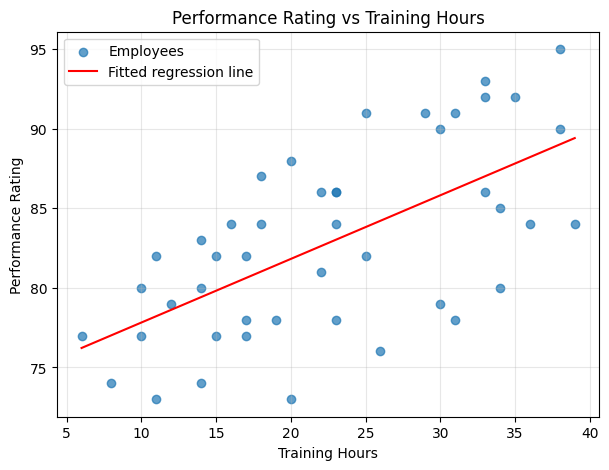

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Step 1: Keep only the two columns and drop rows missing in EITHER one.
# This creates a separate copy, so Employee_Combined itself is not changed.
reg_data = Employee_Combined[["Training_Hours", "Performance_Rating"]].dropna()

x = reg_data["Training_Hours"]        # predictor
y = reg_data["Performance_Rating"]    # outcome

# Step 2: Fit the simple linear regression
result = stats.linregress(x, y)

n = len(reg_data)
intercept = result.intercept
slope = result.slope
r_squared = result.rvalue ** 2
p_value = result.pvalue               # two-sided p-value for the slope

# Step 3: Display the results, rounded to 3 decimal places
print("SIMPLE LINEAR REGRESSION: Performance_Rating ~ Training_Hours")
print("-" * 55)
print(f"Valid observations (n) : {n}")
print(f"Intercept              : {intercept:.3f}")
print(f"Slope                  : {slope:.3f}")
print(f"R-squared              : {r_squared:.3f}")
if p_value < 0.001:
    print("p-value for the slope  : < 0.001")
else:
    print(f"p-value for the slope  : {p_value:.3f}")

# Step 4: Scatterplot with fitted regression line
plt.figure(figsize=(7, 5))
plt.scatter(x, y, alpha=0.7, label="Employees")
x_line = [x.min(), x.max()]
y_line = [intercept + slope * v for v in x_line]
plt.plot(x_line, y_line, color="red", label="Fitted regression line")
plt.xlabel("Training Hours")
plt.ylabel("Performance Rating")
plt.title("Performance Rating vs Training Hours")
plt.legend()
plt.grid(alpha=0.3)
plt.show()